In [1]:
# ============================================================
# CROSSWALK SAFETY v4 — HARD HEARTBEAT
# ============================================================
import os, sys, time

print("=== CROSSWALK SAFETY V4 BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True)
time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)

marker = "/kaggle/working/CROSSWALK_V4_STARTED.txt"
with open(marker, "w", encoding="utf-8") as f:
    f.write("Crosswalk Safety v4 started\n")

print("[BOOT] marker:", marker, flush=True)
print("=== CROSSWALK SAFETY V4 HEARTBEAT OK ===", flush=True)

=== CROSSWALK SAFETY V4 BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
[BOOT] marker: /kaggle/working/CROSSWALK_V4_STARTED.txt
=== CROSSWALK SAFETY V4 HEARTBEAT OK ===


# 8% — Crosswalk Safety v4
## YOLO Bounding-Box Preprocessing → Temporal CNN-BiLSTM

This notebook turns the previous inference-only pipeline into a **custom-trained temporal model**.

### Architecture

```text
traffic video
    ↓
frame sampling (2 s)
    ↓
YOLO11n pretrained COCO
    ↓
bounding-box preprocessing
    ↓
spatial + occupancy + motion features
    ↓
8-step temporal history
    ↓
Temporal Conv1D
    ↓
BiLSTM
    ↓
Binary classifier
    ↓
predict conflict at the NEXT sampled frame
```

### Why this is better than simply training on the current-frame rule

The target is **next-sample conflict**, while the model only receives the previous temporal window.  
Therefore the network is learning a temporal pattern rather than being handed the target rule directly.

### Important scientific limitation

There are no manually validated conflict labels in this dataset. The training target is therefore a **weak/pseudo label** derived from the v3 safety-zone rule:

```text
next_conflict = next frame has
                pedestrian_in_ROI > 0
                AND vehicle_in_ROI > 0
```

So the reported metrics measure agreement with that proxy definition, **not real-world violation accuracy**.

### Professional notebook requirement

This notebook intentionally includes visual previews for:
- video/data audit;
- YOLO bounding-box preprocessing;
- extracted feature table;
- label distribution;
- temporal sequence construction;
- training curves;
- confusion matrix;
- ROC / PR curves;
- sample predictions.

In [2]:
# ============================================================
# 0/15 — PREFLIGHT
# ============================================================
from pathlib import Path

ROOTS = [
    Path("/kaggle/input/datasets/loliwibu/crosswalkpart-1"),
    Path("/kaggle/input/datasets/loliwibu/crosswalk-part-2"),
    Path("/kaggle/input/datasets/loliwibu/crosswalk-part-3"),
]

for root in ROOTS:
    print("[PREFLIGHT]", root, "exists=", root.exists(), flush=True)
    if not root.exists():
        raise FileNotFoundError(root)

    avi = list(root.rglob("*.avi"))
    print("[PREFLIGHT]", root.name, len(avi), "AVI", flush=True)

print("[PREFLIGHT] dataset mounts OK", flush=True)

[PREFLIGHT] /kaggle/input/datasets/loliwibu/crosswalkpart-1 exists= True
[PREFLIGHT] crosswalkpart-1 40 AVI
[PREFLIGHT] /kaggle/input/datasets/loliwibu/crosswalk-part-2 exists= True
[PREFLIGHT] crosswalk-part-2 40 AVI
[PREFLIGHT] /kaggle/input/datasets/loliwibu/crosswalk-part-3 exists= True
[PREFLIGHT] crosswalk-part-3 40 AVI
[PREFLIGHT] dataset mounts OK


In [3]:
# ============================================================
# 1/15 — IMPORTS + CONFIG
# ============================================================
import gc
import json
import math
import random
import shutil
import subprocess
import importlib.util
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

def ensure(package, module):
    if importlib.util.find_spec(module) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package]
        )

ensure("ultralytics>=8.3.0", "ultralytics")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from ultralytics import YOLO

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
)
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUT = Path("/kaggle/working/crosswalk_safety_v4_output")
REP = OUT / "reports"
ASSET = OUT / "assets"
PREVIEW = ASSET / "previews"
MODEL_DIR = OUT / "models"
CACHE = OUT / "cache"

for p in [OUT, REP, ASSET, PREVIEW, MODEL_DIR, CACHE]:
    p.mkdir(parents=True, exist_ok=True)

SAMPLE_EVERY_SECONDS = 2.0
SEQUENCE_LENGTH = 8
PREDICT_HORIZON_STEPS = 1

CONF = 0.25
IOU = 0.50
IMGSZ = 640
MAX_DET = 300

BATCH_SIZE = 128
EPOCHS = 60
PATIENCE = 10
LR = 3e-4
WEIGHT_DECAY = 1e-4

print("[CONFIG] device:", DEVICE, flush=True)
print("[CONFIG] sample_every_seconds:", SAMPLE_EVERY_SECONDS, flush=True)
print("[CONFIG] sequence_length:", SEQUENCE_LENGTH, flush=True)
print("[CONFIG] next-frame horizon:", PREDICT_HORIZON_STEPS, flush=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
[CONFIG] device: cuda
[CONFIG] sample_every_seconds: 2.0
[CONFIG] sequence_length: 8
[CONFIG] next-frame horizon: 1


In [4]:
# ============================================================
# 2/15 — VIDEO AUDIT
# ============================================================
video_files = []

for root in ROOTS:
    vids = sorted(
        [
            p for p in root.rglob("*")
            if p.is_file() and p.suffix.lower() in {".avi", ".mp4", ".mov", ".mkv"}
        ],
        key=lambda p: p.name.lower(),
    )

    print(f"[AUDIT] {root.name}: {len(vids)} videos", flush=True)
    video_files.extend(vids)

video_files = sorted(video_files, key=lambda p: p.name.lower())

assert len(video_files) == 120, f"Expected 120 videos, found {len(video_files)}"

audit_rows = []

for i, path in enumerate(video_files, 1):
    cap = cv2.VideoCapture(str(path))

    opened = cap.isOpened()
    fps = float(cap.get(cv2.CAP_PROP_FPS)) if opened else 0.0
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if opened else 0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) if opened else 0
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) if opened else 0
    ok, _ = cap.read() if opened else (False, None)
    cap.release()

    audit_rows.append({
        "video": path.name,
        "path": str(path),
        "opened": opened,
        "first_frame_readable": bool(ok),
        "fps": fps,
        "frame_count": frames,
        "width": width,
        "height": height,
        "duration_seconds": frames / fps if fps > 0 else 0.0,
    })

    if i == 1 or i % 20 == 0 or i == len(video_files):
        print(f"[AUDIT] {i}/120 {path.name} opened={opened} frame={ok}", flush=True)

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(REP / "video_audit.csv", index=False)

bad = audit_df[
    (~audit_df["opened"]) | (~audit_df["first_frame_readable"])
]

assert len(bad) == 0, f"Unreadable videos: {len(bad)}"

print("[AUDIT] all 120 videos readable", flush=True)

display(
    audit_df[
        ["video", "fps", "frame_count", "width", "height", "duration_seconds"]
    ].head(10)
)

[AUDIT] crosswalkpart-1: 40 videos
[AUDIT] crosswalk-part-2: 40 videos
[AUDIT] crosswalk-part-3: 40 videos
[AUDIT] 1/120 video_001.avi opened=True frame=True
[AUDIT] 20/120 video_020.avi opened=True frame=True
[AUDIT] 40/120 video_040.avi opened=True frame=True
[AUDIT] 60/120 video_060.avi opened=True frame=True
[AUDIT] 80/120 video_080.avi opened=True frame=True
[AUDIT] 100/120 video_100.avi opened=True frame=True
[AUDIT] 120/120 video_120.avi opened=True frame=True
[AUDIT] all 120 videos readable


,video,fps,frame_count,width,height,duration_seconds
0,video_001.avi,30.0,9000,1200,1100,300.0
1,video_002.avi,30.0,9000,1200,1100,300.0
2,video_003.avi,30.0,9000,1200,1100,300.0
3,video_004.avi,30.0,9000,1200,1100,300.0
4,video_005.avi,30.0,9000,1200,1100,300.0
5,video_006.avi,30.0,9000,1200,1100,300.0
6,video_007.avi,30.0,9000,1200,1100,300.0
7,video_008.avi,30.0,9000,1200,1100,300.0
8,video_009.avi,30.0,9000,1200,1100,300.0
9,video_010.avi,30.0,9000,1200,1100,300.0


## Preview 1 — Raw dataset inspection

The next cell displays representative raw frames before any detector output is used.  
This makes the notebook understandable even to someone opening it only to inspect the workflow.

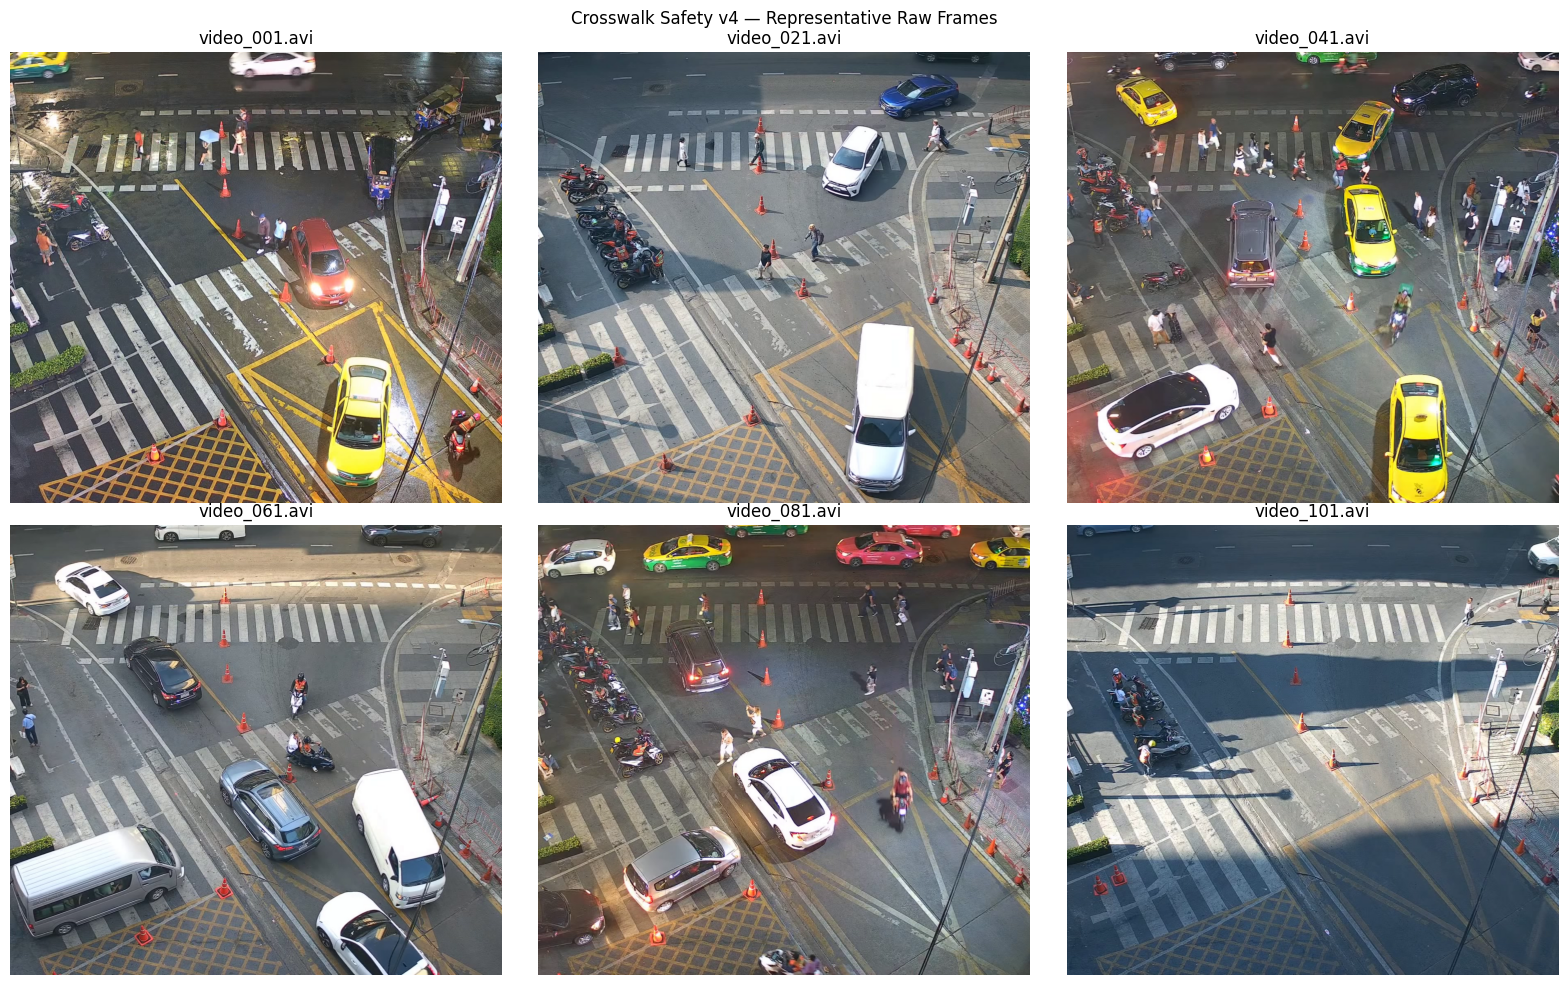

In [5]:
# ============================================================
# 3/15 — PREVIEW RAW VIDEO FRAMES
# ============================================================
preview_indices = [0, 20, 40, 60, 80, 100]

plt.figure(figsize=(16, 10))

for plot_i, video_i in enumerate(preview_indices, 1):
    path = video_files[video_i]
    cap = cv2.VideoCapture(str(path))
    ok, frame = cap.read()
    cap.release()

    if not ok:
        continue

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, plot_i)
    plt.imshow(frame_rgb)
    plt.title(path.name)
    plt.axis("off")

plt.suptitle("Crosswalk Safety v4 — Representative Raw Frames")
plt.tight_layout()
plt.savefig(PREVIEW / "raw_video_preview.png", dpi=160, bbox_inches="tight")
plt.show()

In [6]:
# ============================================================
# 4/15 — YOLO + ROI + FEATURE HELPERS
# ============================================================
model = YOLO("yolo11n.pt")

PERSON = 0
VEHICLES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck",
}
TARGET = [PERSON] + list(VEHICLES.keys())

DEFAULT_ROI = np.array(
    [
        [0.12, 0.62],
        [0.88, 0.62],
        [0.98, 0.96],
        [0.02, 0.96],
    ],
    dtype=np.float32,
)

ROI_OVERRIDES = {}

def roi_px(video_name, width, height):
    pts = np.asarray(
        ROI_OVERRIDES.get(video_name, DEFAULT_ROI),
        dtype=np.float32,
    ).copy()

    pts[:, 0] *= width
    pts[:, 1] *= height

    return pts.astype(np.int32)

def point_inside(point, polygon):
    return (
        cv2.pointPolygonTest(
            polygon.astype(np.float32),
            (float(point[0]), float(point[1])),
            False,
        )
        >= 0
    )

def bbox_features(xyxy, width, height):
    x1, y1, x2, y2 = map(float, xyxy)

    cx = ((x1 + x2) / 2.0) / width
    cy = ((y1 + y2) / 2.0) / height
    bw = max(x2 - x1, 0.0) / width
    bh = max(y2 - y1, 0.0) / height
    area = bw * bh

    return cx, cy, bw, bh, area

def safe_mean(values, default=0.0):
    return float(np.mean(values)) if len(values) else float(default)

def safe_min(values, default=1.5):
    return float(np.min(values)) if len(values) else float(default)

def analyze_frame(frame, video_name):
    height, width = frame.shape[:2]
    polygon = roi_px(video_name, width, height)

    result = model.predict(
        frame,
        imgsz=IMGSZ,
        conf=CONF,
        iou=IOU,
        classes=TARGET,
        max_det=MAX_DET,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False,
    )[0]

    detections = []
    person_anchors = []
    vehicle_anchors = []

    person_cx = []
    person_cy = []
    person_area = []

    vehicle_cx = []
    vehicle_cy = []
    vehicle_area = []

    persons_total = 0
    vehicles_total = 0
    pedestrians_in_zone = 0
    vehicles_in_zone = 0

    if result.boxes is not None:
        for box in result.boxes:
            cls = int(box.cls[0].item())
            conf = float(box.conf[0].item())

            xyxy = box.xyxy[0].detach().cpu().tolist()
            x1, y1, x2, y2 = map(float, xyxy)

            is_person = cls == PERSON
            is_vehicle = cls in VEHICLES

            cx, cy, bw, bh, area = bbox_features(
                xyxy,
                width,
                height,
            )

            anchor_px = ((x1 + x2) / 2.0, y2)
            anchor_norm = (
                anchor_px[0] / width,
                anchor_px[1] / height,
            )

            inside = point_inside(anchor_px, polygon)

            if is_person:
                persons_total += 1
                pedestrians_in_zone += int(inside)

                person_anchors.append(anchor_norm)
                person_cx.append(cx)
                person_cy.append(cy)
                person_area.append(area)

            elif is_vehicle:
                vehicles_total += 1
                vehicles_in_zone += int(inside)

                vehicle_anchors.append(anchor_norm)
                vehicle_cx.append(cx)
                vehicle_cy.append(cy)
                vehicle_area.append(area)

            detections.append({
                "name": result.names.get(cls, str(cls)),
                "conf": conf,
                "xyxy": xyxy,
                "is_person": is_person,
                "is_vehicle": is_vehicle,
                "inside": inside,
                "anchor_px": anchor_px,
            })

    pair_distances = []

    for px, py in person_anchors:
        for vx, vy in vehicle_anchors:
            pair_distances.append(
                math.sqrt(
                    (px - vx) ** 2
                    + (py - vy) ** 2
                )
            )

    min_pv_distance = safe_min(pair_distances)
    mean_pv_distance = safe_mean(pair_distances, default=1.5)

    conflict_proxy = (
        pedestrians_in_zone > 0
        and vehicles_in_zone > 0
    )

    feature = {
        "persons_total": persons_total,
        "vehicles_total": vehicles_total,
        "pedestrians_in_zone": pedestrians_in_zone,
        "vehicles_in_zone": vehicles_in_zone,

        "person_mean_cx": safe_mean(person_cx),
        "person_mean_cy": safe_mean(person_cy),
        "person_mean_area": safe_mean(person_area),

        "vehicle_mean_cx": safe_mean(vehicle_cx),
        "vehicle_mean_cy": safe_mean(vehicle_cy),
        "vehicle_mean_area": safe_mean(vehicle_area),

        "min_person_vehicle_distance": min_pv_distance,
        "mean_person_vehicle_distance": mean_pv_distance,

        "conflict_proxy": int(conflict_proxy),
    }

    return feature, detections, polygon

def draw_preprocessing_preview(
    frame,
    detections,
    polygon,
    title="",
):
    out = frame.copy()
    overlay = out.copy()

    cv2.fillPoly(
        overlay,
        [polygon.reshape(-1, 1, 2)],
        (0, 255, 255),
    )

    out = cv2.addWeighted(
        overlay,
        0.12,
        out,
        0.88,
        0,
    )

    cv2.polylines(
        out,
        [polygon.reshape(-1, 1, 2)],
        True,
        (0, 255, 255),
        3,
    )

    for det in detections:
        x1, y1, x2, y2 = map(int, det["xyxy"])

        if det["is_vehicle"] and det["inside"]:
            color = (0, 0, 255)
        elif det["is_person"] and det["inside"]:
            color = (0, 255, 0)
        else:
            color = (255, 120, 0)

        cv2.rectangle(
            out,
            (x1, y1),
            (x2, y2),
            color,
            2,
        )

        cv2.circle(
            out,
            (
                int(det["anchor_px"][0]),
                int(det["anchor_px"][1]),
            ),
            4,
            color,
            -1,
        )

        cv2.putText(
            out,
            f"{det['name']} {det['conf']:.2f}",
            (x1, max(18, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            color,
            2,
            cv2.LINE_AA,
        )

    return out

print("[MODEL] YOLO11n pretrained COCO ready", flush=True)

[MODEL] YOLO11n pretrained COCO ready


## Preview 2 — Bounding-box preprocessing

This is the actual preprocessing stage used before custom temporal training.

The preview shows:
- YOLO bounding boxes;
- bottom-center anchor points;
- configured ROI;
- person / vehicle spatial relationships.

The custom model does **not** receive raw pixels. It receives the engineered temporal features extracted from this stage.

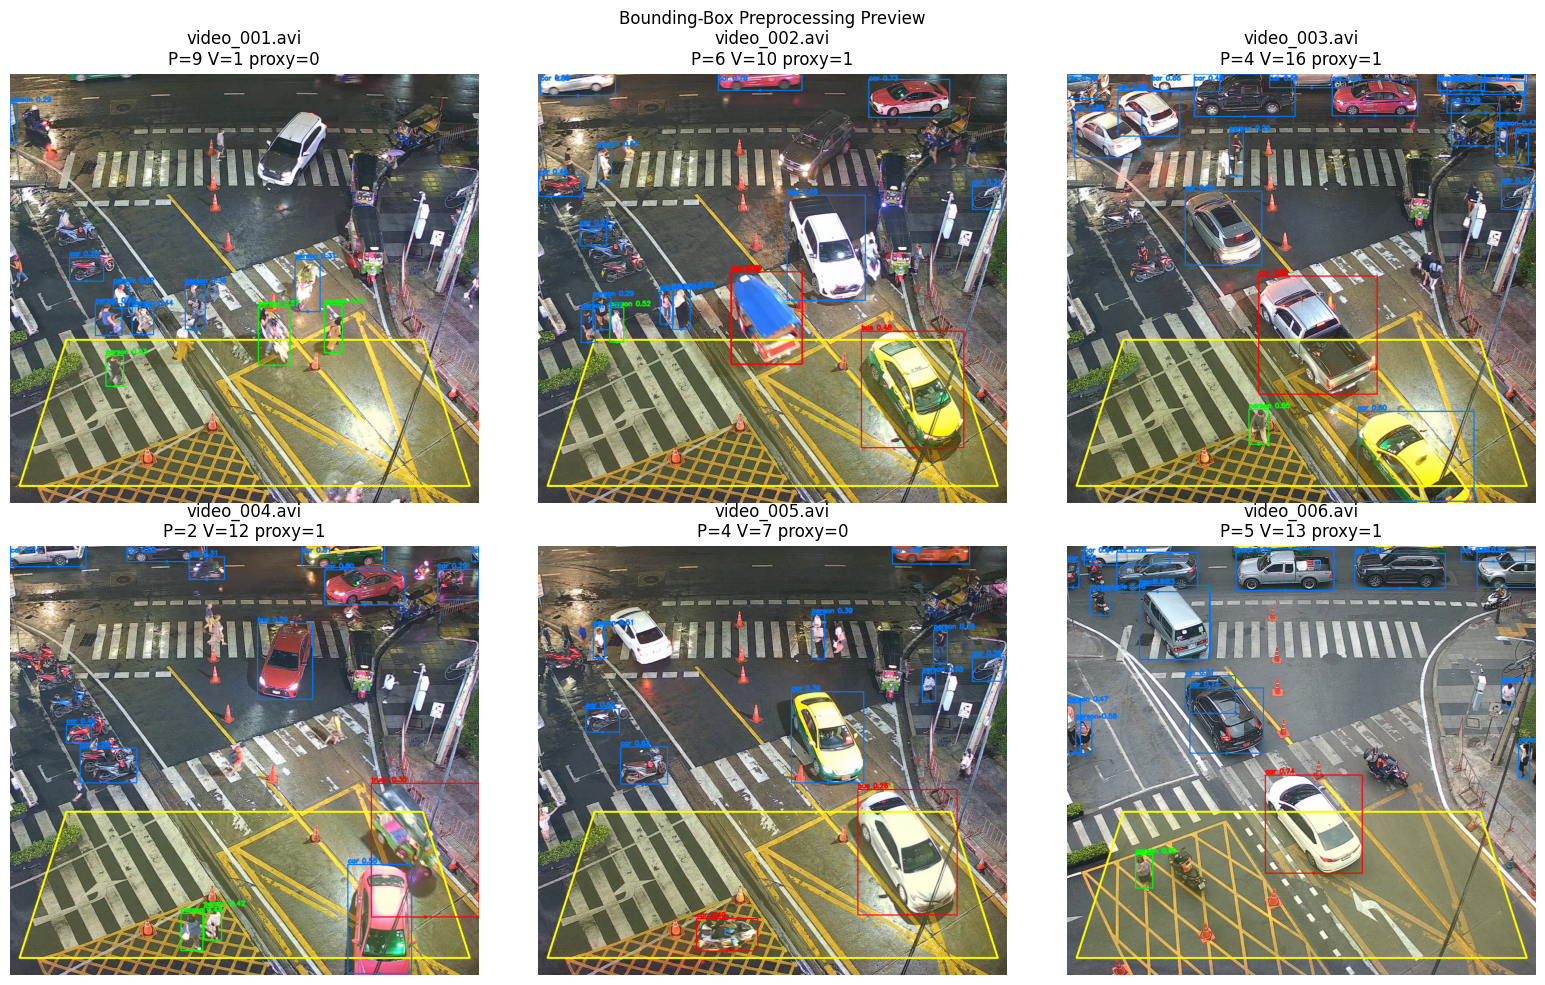

In [7]:
# ============================================================
# 5/15 — PREVIEW YOLO BOUNDING-BOX PREPROCESSING
# ============================================================
preview_videos = video_files[:6]

plt.figure(figsize=(16, 10))

for i, path in enumerate(preview_videos, 1):
    cap = cv2.VideoCapture(str(path))

    fps = float(cap.get(cv2.CAP_PROP_FPS))
    if fps <= 0:
        fps = 25.0

    # Preview from around 60 seconds when possible.
    cap.set(cv2.CAP_PROP_POS_MSEC, 60_000)

    ok, frame = cap.read()
    cap.release()

    if not ok:
        continue

    feature, detections, polygon = analyze_frame(
        frame,
        path.name,
    )

    preview = draw_preprocessing_preview(
        frame,
        detections,
        polygon,
    )

    preview = cv2.cvtColor(
        preview,
        cv2.COLOR_BGR2RGB,
    )

    plt.subplot(2, 3, i)
    plt.imshow(preview)
    plt.title(
        f"{path.name}\n"
        f"P={feature['persons_total']} "
        f"V={feature['vehicles_total']} "
        f"proxy={feature['conflict_proxy']}"
    )
    plt.axis("off")

plt.suptitle("Bounding-Box Preprocessing Preview")
plt.tight_layout()
plt.savefig(
    PREVIEW / "bbox_preprocessing_preview.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [8]:
# ============================================================
# 6/15 — FULL PREPROCESSING OF ALL 120 VIDEOS
# ============================================================
FEATURE_CACHE = CACHE / "frame_features.csv"

if FEATURE_CACHE.exists():
    print("[CACHE] Loading existing frame features:", FEATURE_CACHE, flush=True)
    frame_df = pd.read_csv(FEATURE_CACHE)

else:
    frame_rows = []
    global_start = time.time()

    for vi, path in enumerate(video_files, 1):
        cap = cv2.VideoCapture(str(path))

        fps = float(cap.get(cv2.CAP_PROP_FPS))
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if fps <= 0:
            fps = 25.0

        step = max(
            1,
            int(round(fps * SAMPLE_EVERY_SECONDS)),
        )

        frame_index = 0
        sampled = 0

        print(
            f"[PREPROCESS][{vi:03d}/120] START "
            f"{path.name} fps={fps:.2f} step={step}",
            flush=True,
        )

        while True:
            grabbed = cap.grab()

            if not grabbed:
                break

            if frame_index % step != 0:
                frame_index += 1
                continue

            ok, frame = cap.retrieve()

            if not ok:
                frame_index += 1
                continue

            timestamp = frame_index / fps

            feature, _, _ = analyze_frame(
                frame,
                path.name,
            )

            frame_rows.append({
                "video": path.name,
                "frame_index": frame_index,
                "timestamp_seconds": float(timestamp),
                **feature,
            })

            sampled += 1

            if sampled == 1 or sampled % 50 == 0:
                print(
                    f"[PREPROCESS][{path.name}] "
                    f"sampled={sampled} "
                    f"t={timestamp:.1f}s",
                    flush=True,
                )

            frame_index += 1

        cap.release()

        # Incremental save: safer for long Kaggle runs.
        pd.DataFrame(frame_rows).to_csv(
            FEATURE_CACHE,
            index=False,
        )

        print(
            f"[PREPROCESS][{vi:03d}/120] END "
            f"{path.name} sampled={sampled}",
            flush=True,
        )

    frame_df = pd.DataFrame(frame_rows)

    print(
        "[PREPROCESS] COMPLETE "
        f"elapsed={(time.time()-global_start)/60:.1f} min",
        flush=True,
    )

frame_df = frame_df.sort_values(
    ["video", "timestamp_seconds"]
).reset_index(drop=True)

print("[PREPROCESS] rows:", len(frame_df), flush=True)
print("[PREPROCESS] videos:", frame_df["video"].nunique(), flush=True)

assert frame_df["video"].nunique() == 120
assert len(frame_df) > 0

frame_df.to_csv(
    REP / "frame_features.csv",
    index=False,
)

display(frame_df.head(12))

[PREPROCESS][001/120] START video_001.avi fps=30.00 step=60
[PREPROCESS][video_001.avi] sampled=1 t=0.0s
[PREPROCESS][video_001.avi] sampled=50 t=98.0s
[PREPROCESS][video_001.avi] sampled=100 t=198.0s
[PREPROCESS][video_001.avi] sampled=150 t=298.0s
[PREPROCESS][001/120] END video_001.avi sampled=150
[PREPROCESS][002/120] START video_002.avi fps=30.00 step=60
[PREPROCESS][video_002.avi] sampled=1 t=0.0s
[PREPROCESS][video_002.avi] sampled=50 t=98.0s
[PREPROCESS][video_002.avi] sampled=100 t=198.0s
[PREPROCESS][video_002.avi] sampled=150 t=298.0s
[PREPROCESS][002/120] END video_002.avi sampled=150
[PREPROCESS][003/120] START video_003.avi fps=30.00 step=60
[PREPROCESS][video_003.avi] sampled=1 t=0.0s
[PREPROCESS][video_003.avi] sampled=50 t=98.0s
[PREPROCESS][video_003.avi] sampled=100 t=198.0s
[PREPROCESS][video_003.avi] sampled=150 t=298.0s
[PREPROCESS][003/120] END video_003.avi sampled=150
[PREPROCESS][004/120] START video_004.avi fps=30.00 step=60
[PREPROCESS][video_004.avi] sample

[mpeg1video @ 0x22aad940] ac-tex damaged at 73 35
[mpeg1video @ 0x22aad940] Warning MVs not available


[PREPROCESS][video_108.avi] sampled=100 t=198.0s
[PREPROCESS][video_108.avi] sampled=150 t=298.0s
[PREPROCESS][108/120] END video_108.avi sampled=150
[PREPROCESS][109/120] START video_109.avi fps=30.00 step=60
[PREPROCESS][video_109.avi] sampled=1 t=0.0s
[PREPROCESS][video_109.avi] sampled=50 t=98.0s
[PREPROCESS][video_109.avi] sampled=100 t=198.0s
[PREPROCESS][video_109.avi] sampled=150 t=298.0s
[PREPROCESS][109/120] END video_109.avi sampled=150
[PREPROCESS][110/120] START video_110.avi fps=30.00 step=60
[PREPROCESS][video_110.avi] sampled=1 t=0.0s
[PREPROCESS][video_110.avi] sampled=50 t=98.0s
[PREPROCESS][video_110.avi] sampled=100 t=198.0s
[PREPROCESS][video_110.avi] sampled=150 t=298.0s
[PREPROCESS][110/120] END video_110.avi sampled=150
[PREPROCESS][111/120] START video_111.avi fps=30.00 step=60
[PREPROCESS][video_111.avi] sampled=1 t=0.0s
[PREPROCESS][video_111.avi] sampled=50 t=98.0s
[PREPROCESS][video_111.avi] sampled=100 t=198.0s
[PREPROCESS][video_111.avi] sampled=150 t=298

,video,frame_index,timestamp_seconds,persons_total,vehicles_total,pedestrians_in_zone,vehicles_in_zone,person_mean_cx,person_mean_cy,person_mean_area,vehicle_mean_cx,vehicle_mean_cy,vehicle_mean_area,min_person_vehicle_distance,mean_person_vehicle_distance,conflict_proxy
0,video_001.avi,0,0.0,3,5,0,0,0.378418,0.411970,0.002508,0.528506,0.434490,0.025945,0.155064,0.516132,0
1,video_001.avi,60,2.0,5,3,0,0,0.208136,0.403915,0.002961,0.675314,0.452118,0.028816,0.203499,0.609230,0
2,video_001.avi,120,4.0,7,5,0,0,0.275988,0.386855,0.002730,0.583043,0.376405,0.024878,0.175849,0.569252,0
3,video_001.avi,180,6.0,3,4,2,0,0.167519,0.560811,0.002851,0.496958,0.590878,0.021051,0.307411,0.543109,0
4,video_001.avi,240,8.0,2,5,1,2,0.064295,0.458611,0.004323,0.520952,0.649753,0.023321,0.172343,0.677118,1
5,video_001.avi,300,10.0,0,5,0,2,0.000000,0.000000,0.000000,0.495726,0.763457,0.027528,1.500000,1.500000,0
6,video_001.avi,360,12.0,1,4,0,2,0.600729,0.210297,0.003170,0.523329,0.566634,0.035609,0.353223,0.528992,0
7,video_001.avi,420,14.0,3,6,0,2,0.409346,0.252817,0.003982,0.519930,0.588963,0.028717,0.155476,0.488930,0
8,video_001.avi,480,16.0,0,7,0,2,0.000000,0.000000,0.000000,0.407016,0.589465,0.026670,1.500000,1.500000,0
9,video_001.avi,540,18.0,0,7,0,3,0.000000,0.000000,0.000000,0.570433,0.564269,0.030072,1.500000,1.500000,0


## Preview 3 — Engineered features

The table below is the bridge between computer-vision preprocessing and deep-learning training.

Each sampled frame becomes a compact numeric representation including:
- counts;
- ROI occupancy;
- normalized object position;
- normalized bounding-box area;
- person–vehicle spatial distance;
- temporal motion features added in the next cell.

[FEATURES] feature count: 21
['persons_total', 'vehicles_total', 'pedestrians_in_zone', 'vehicles_in_zone', 'person_mean_cx', 'person_mean_cy', 'person_mean_area', 'vehicle_mean_cx', 'vehicle_mean_cy', 'vehicle_mean_area', 'min_person_vehicle_distance', 'mean_person_vehicle_distance', 'delta_persons_total', 'delta_vehicles_total', 'delta_pedestrians_in_zone', 'delta_vehicles_in_zone', 'delta_person_mean_cx', 'delta_person_mean_cy', 'delta_vehicle_mean_cx', 'delta_vehicle_mean_cy', 'delta_min_person_vehicle_distance']


,video,timestamp_seconds,conflict_proxy,persons_total,vehicles_total,pedestrians_in_zone,vehicles_in_zone,person_mean_cx,person_mean_cy,person_mean_area,...,mean_person_vehicle_distance,delta_persons_total,delta_vehicles_total,delta_pedestrians_in_zone,delta_vehicles_in_zone,delta_person_mean_cx,delta_person_mean_cy,delta_vehicle_mean_cx,delta_vehicle_mean_cy,delta_min_person_vehicle_distance
0,video_001.avi,0.0,0,3,5,0,0,0.378418,0.411970,0.002508,...,0.516132,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
1,video_001.avi,2.0,0,5,3,0,0,0.208136,0.403915,0.002961,...,0.609230,2.0,-2.0,0.0,0.0,-0.170282,-0.008055,0.146808,0.017628,0.048435
2,video_001.avi,4.0,0,7,5,0,0,0.275988,0.386855,0.002730,...,0.569252,2.0,2.0,0.0,0.0,0.067852,-0.017061,-0.092271,-0.075713,-0.027650
3,video_001.avi,6.0,0,3,4,2,0,0.167519,0.560811,0.002851,...,0.543109,-4.0,-1.0,2.0,0.0,-0.108468,0.173956,-0.086085,0.214473,0.131562
4,video_001.avi,8.0,1,2,5,1,2,0.064295,0.458611,0.004323,...,0.677118,-1.0,1.0,-1.0,2.0,-0.103224,-0.102200,0.023993,0.058875,-0.135068
5,video_001.avi,10.0,0,0,5,0,2,0.000000,0.000000,0.000000,...,1.500000,-2.0,0.0,-1.0,0.0,-0.064295,-0.458611,-0.025226,0.113704,1.327657
6,video_001.avi,12.0,0,1,4,0,2,0.600729,0.210297,0.003170,...,0.528992,1.0,-1.0,0.0,0.0,0.600729,0.210297,0.027603,-0.196824,-1.146777
7,video_001.avi,14.0,0,3,6,0,2,0.409346,0.252817,0.003982,...,0.488930,2.0,2.0,0.0,0.0,-0.191383,0.042520,-0.003399,0.022329,-0.197747
8,video_001.avi,16.0,0,0,7,0,2,0.000000,0.000000,0.000000,...,1.500000,-3.0,1.0,0.0,0.0,-0.409346,-0.252817,-0.112914,0.000502,1.344524
9,video_001.avi,18.0,0,0,7,0,3,0.000000,0.000000,0.000000,...,1.500000,0.0,0.0,0.0,1.0,0.000000,0.000000,0.163417,-0.025197,0.000000


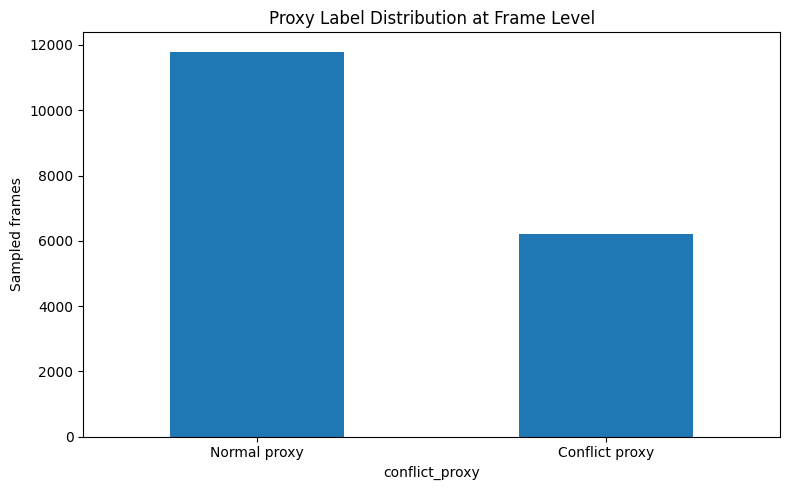

In [9]:
# ============================================================
# 7/15 — TEMPORAL FEATURE ENGINEERING + PREVIEW
# ============================================================
BASE_FEATURES = [
    "persons_total",
    "vehicles_total",
    "pedestrians_in_zone",
    "vehicles_in_zone",
    "person_mean_cx",
    "person_mean_cy",
    "person_mean_area",
    "vehicle_mean_cx",
    "vehicle_mean_cy",
    "vehicle_mean_area",
    "min_person_vehicle_distance",
    "mean_person_vehicle_distance",
]

MOTION_SOURCE = [
    "persons_total",
    "vehicles_total",
    "pedestrians_in_zone",
    "vehicles_in_zone",
    "person_mean_cx",
    "person_mean_cy",
    "vehicle_mean_cx",
    "vehicle_mean_cy",
    "min_person_vehicle_distance",
]

for feature_name in MOTION_SOURCE:
    frame_df[f"delta_{feature_name}"] = (
        frame_df
        .groupby("video")[feature_name]
        .diff()
        .fillna(0.0)
    )

DELTA_FEATURES = [
    f"delta_{feature_name}"
    for feature_name in MOTION_SOURCE
]

FEATURE_COLUMNS = BASE_FEATURES + DELTA_FEATURES

frame_df[FEATURE_COLUMNS] = (
    frame_df[FEATURE_COLUMNS]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

frame_df.to_csv(
    REP / "frame_features_with_motion.csv",
    index=False,
)

print("[FEATURES] feature count:", len(FEATURE_COLUMNS), flush=True)
print(FEATURE_COLUMNS, flush=True)

display(
    frame_df[
        ["video", "timestamp_seconds", "conflict_proxy"]
        + FEATURE_COLUMNS
    ].head(15)
)

plt.figure(figsize=(8, 5))
frame_df["conflict_proxy"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Normal proxy", "Conflict proxy"], rotation=0)
plt.ylabel("Sampled frames")
plt.title("Proxy Label Distribution at Frame Level")
plt.tight_layout()
plt.savefig(PREVIEW / "frame_proxy_distribution.png", dpi=160)
plt.show()

In [10]:
# ============================================================
# 8/15 — VIDEO-LEVEL TRAIN / VAL / TEST SPLIT
# ============================================================
# Split by VIDEO, never by individual frames/sequences.
# This prevents neighboring frames from the same video leaking across splits.

video_stats = (
    frame_df
    .groupby("video")
    .agg(
        sampled_frames=("conflict_proxy", "size"),
        conflict_rate=("conflict_proxy", "mean"),
    )
    .reset_index()
)

video_stats["rate_bin"] = pd.qcut(
    video_stats["conflict_rate"],
    q=5,
    labels=False,
    duplicates="drop",
)

rng = np.random.default_rng(SEED)

train_videos = []
val_videos = []
test_videos = []

for _, group in video_stats.groupby("rate_bin"):
    names = group["video"].to_numpy().copy()
    rng.shuffle(names)

    n = len(names)
    n_test = max(1, int(round(n * 0.10)))
    n_val = max(1, int(round(n * 0.15)))

    test_videos.extend(names[:n_test].tolist())
    val_videos.extend(names[n_test:n_test+n_val].tolist())
    train_videos.extend(names[n_test+n_val:].tolist())

# Ensure exact disjointness.
train_videos = sorted(set(train_videos))
val_videos = sorted(set(val_videos) - set(train_videos))
test_videos = sorted(
    set(test_videos)
    - set(train_videos)
    - set(val_videos)
)

all_assigned = set(train_videos) | set(val_videos) | set(test_videos)

if len(all_assigned) != 120:
    missing = sorted(
        set(video_stats["video"])
        - all_assigned
    )
    train_videos.extend(missing)

print(
    f"[SPLIT] train videos={len(train_videos)} "
    f"val videos={len(val_videos)} "
    f"test videos={len(test_videos)}",
    flush=True,
)

assert not (set(train_videos) & set(val_videos))
assert not (set(train_videos) & set(test_videos))
assert not (set(val_videos) & set(test_videos))
assert len(set(train_videos) | set(val_videos) | set(test_videos)) == 120

split_map = {}

for v in train_videos:
    split_map[v] = "train"
for v in val_videos:
    split_map[v] = "val"
for v in test_videos:
    split_map[v] = "test"

video_stats["split"] = video_stats["video"].map(split_map)
video_stats.to_csv(REP / "video_split.csv", index=False)

display(
    video_stats.groupby("split").agg(
        videos=("video", "count"),
        mean_conflict_rate=("conflict_rate", "mean"),
        min_conflict_rate=("conflict_rate", "min"),
        max_conflict_rate=("conflict_rate", "max"),
    )
)

[SPLIT] train videos=91 val videos=19 test videos=10


,videos,mean_conflict_rate,min_conflict_rate,max_conflict_rate
split,,,,
test,10,0.350667,0.113333,0.673333
train,91,0.346007,0.013333,0.820000
val,19,0.334386,0.026667,0.740000


In [11]:
# ============================================================
# 9/15 — BUILD TEMPORAL SEQUENCES
# ============================================================
def build_sequences(df, allowed_videos):
    X = []
    y = []
    meta = []

    allowed = set(allowed_videos)

    for video, group in df[df["video"].isin(allowed)].groupby("video"):
        group = group.sort_values("timestamp_seconds").reset_index(drop=True)

        features = group[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
        targets = group["conflict_proxy"].to_numpy(dtype=np.float32)
        times = group["timestamp_seconds"].to_numpy(dtype=np.float32)

        max_start = (
            len(group)
            - SEQUENCE_LENGTH
            - PREDICT_HORIZON_STEPS
            + 1
        )

        for start in range(max(0, max_start)):
            end = start + SEQUENCE_LENGTH
            target_index = (
                end
                + PREDICT_HORIZON_STEPS
                - 1
            )

            X.append(features[start:end])
            y.append(targets[target_index])

            meta.append({
                "video": video,
                "history_start_seconds": float(times[start]),
                "history_end_seconds": float(times[end - 1]),
                "target_seconds": float(times[target_index]),
                "target": int(targets[target_index]),
            })

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DataFrame(meta),
    )

X_train, y_train, meta_train = build_sequences(
    frame_df,
    train_videos,
)

X_val, y_val, meta_val = build_sequences(
    frame_df,
    val_videos,
)

X_test, y_test, meta_test = build_sequences(
    frame_df,
    test_videos,
)

print("[SEQUENCES]")
print(" train:", X_train.shape, y_train.shape)
print(" val  :", X_val.shape, y_val.shape)
print(" test :", X_test.shape, y_test.shape)

assert X_train.ndim == 3
assert X_train.shape[1] == SEQUENCE_LENGTH
assert X_train.shape[2] == len(FEATURE_COLUMNS)

for name, labels in [
    ("train", y_train),
    ("val", y_val),
    ("test", y_test),
]:
    positive_rate = float(labels.mean()) if len(labels) else 0.0
    print(
        f"[SEQUENCES] {name} positive rate={positive_rate:.3f}",
        flush=True,
    )

display(meta_train.head(10))

[SEQUENCES]
 train: (12922, 8, 21) (12922,)
 val  : (2698, 8, 21) (2698,)
 test : (1420, 8, 21) (1420,)
[SEQUENCES] train positive rate=0.346
[SEQUENCES] val positive rate=0.339
[SEQUENCES] test positive rate=0.353


,video,history_start_seconds,history_end_seconds,target_seconds,target
0,video_001.avi,0.0,14.0,16.0,0
1,video_001.avi,2.0,16.0,18.0,0
2,video_001.avi,4.0,18.0,20.0,0
3,video_001.avi,6.0,20.0,22.0,0
4,video_001.avi,8.0,22.0,24.0,0
5,video_001.avi,10.0,24.0,26.0,0
6,video_001.avi,12.0,26.0,28.0,0
7,video_001.avi,14.0,28.0,30.0,0
8,video_001.avi,16.0,30.0,32.0,0
9,video_001.avi,18.0,32.0,34.0,0


## Preview 4 — Temporal sequence sample

Each training example contains the previous **8 sampled frames** (16 seconds at the default 2-second sampling interval).  
The target is the conflict proxy at the **next sampled frame**.

In [12]:
# ============================================================
# 10/15 — SEQUENCE PREVIEW + SCALING
# ============================================================
example_index = 0

example = pd.DataFrame(
    X_train[example_index],
    columns=FEATURE_COLUMNS,
)

example.insert(
    0,
    "step",
    np.arange(SEQUENCE_LENGTH),
)

print("[SEQUENCE PREVIEW]")
display(example)

print("[TARGET META]")
display(meta_train.iloc[[example_index]])

# Fit scaler on TRAIN FRAMES ONLY.
scaler = StandardScaler()

flat_train = X_train.reshape(
    -1,
    X_train.shape[-1],
)

scaler.fit(flat_train)

def apply_scaler(X):
    shape = X.shape

    scaled = scaler.transform(
        X.reshape(-1, shape[-1])
    )

    return scaled.reshape(shape).astype(np.float32)

X_train_s = apply_scaler(X_train)
X_val_s = apply_scaler(X_val)
X_test_s = apply_scaler(X_test)

np.save(
    MODEL_DIR / "feature_mean.npy",
    scaler.mean_.astype(np.float32),
)

np.save(
    MODEL_DIR / "feature_scale.npy",
    scaler.scale_.astype(np.float32),
)

print("[SCALER] fit on training split only", flush=True)

[SEQUENCE PREVIEW]


,step,persons_total,vehicles_total,pedestrians_in_zone,vehicles_in_zone,person_mean_cx,person_mean_cy,person_mean_area,vehicle_mean_cx,vehicle_mean_cy,...,mean_person_vehicle_distance,delta_persons_total,delta_vehicles_total,delta_pedestrians_in_zone,delta_vehicles_in_zone,delta_person_mean_cx,delta_person_mean_cy,delta_vehicle_mean_cx,delta_vehicle_mean_cy,delta_min_person_vehicle_distance
0,0,3.0,5.0,0.0,0.0,0.378418,0.411970,0.002508,0.528506,0.434490,...,0.516132,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,5.0,3.0,0.0,0.0,0.208136,0.403915,0.002961,0.675314,0.452118,...,0.609230,2.0,-2.0,0.0,0.0,-0.170282,-0.008055,0.146808,0.017628,0.048435
2,2,7.0,5.0,0.0,0.0,0.275988,0.386855,0.002730,0.583043,0.376405,...,0.569252,2.0,2.0,0.0,0.0,0.067852,-0.017061,-0.092271,-0.075713,-0.027650
3,3,3.0,4.0,2.0,0.0,0.167519,0.560811,0.002851,0.496958,0.590878,...,0.543109,-4.0,-1.0,2.0,0.0,-0.108468,0.173956,-0.086085,0.214473,0.131562
4,4,2.0,5.0,1.0,2.0,0.064295,0.458611,0.004323,0.520952,0.649753,...,0.677118,-1.0,1.0,-1.0,2.0,-0.103224,-0.102200,0.023993,0.058875,-0.135068
5,5,0.0,5.0,0.0,2.0,0.000000,0.000000,0.000000,0.495726,0.763457,...,1.500000,-2.0,0.0,-1.0,0.0,-0.064295,-0.458611,-0.025226,0.113704,1.327657
6,6,1.0,4.0,0.0,2.0,0.600729,0.210297,0.003170,0.523329,0.566634,...,0.528992,1.0,-1.0,0.0,0.0,0.600729,0.210297,0.027603,-0.196824,-1.146777
7,7,3.0,6.0,0.0,2.0,0.409346,0.252817,0.003982,0.519930,0.588963,...,0.488930,2.0,2.0,0.0,0.0,-0.191383,0.042520,-0.003399,0.022329,-0.197747


[TARGET META]


,video,history_start_seconds,history_end_seconds,target_seconds,target
0,video_001.avi,0.0,14.0,16.0,0


[SCALER] fit on training split only


In [13]:
# ============================================================
# 11/15 — DATASET + TEMPORAL CNN-BiLSTM MODEL
# ============================================================
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


train_ds = SequenceDataset(
    X_train_s,
    y_train,
)

val_ds = SequenceDataset(
    X_val_s,
    y_val,
)

test_ds = SequenceDataset(
    X_test_s,
    y_test,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)


class TemporalConflictNet(nn.Module):
    def __init__(
        self,
        input_dim,
        conv_channels=64,
        hidden_size=96,
        dropout=0.25,
    ):
        super().__init__()

        self.temporal = nn.Sequential(
            nn.Conv1d(
                input_dim,
                conv_channels,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm1d(conv_channels),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                conv_channels,
                conv_channels,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm1d(conv_channels),
            nn.GELU(),
        )

        self.bilstm = nn.LSTM(
            input_size=conv_channels,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )

        self.head = nn.Sequential(
            nn.LayerNorm(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        # x: [B, T, F]
        x = x.transpose(1, 2)   # [B, F, T]
        x = self.temporal(x)
        x = x.transpose(1, 2)   # [B, T, C]

        x, _ = self.bilstm(x)

        # Last temporal state summarizes history.
        x = x[:, -1, :]

        return self.head(x).squeeze(1)


net = TemporalConflictNet(
    input_dim=len(FEATURE_COLUMNS),
).to(DEVICE)

with torch.no_grad():
    dummy = torch.zeros(
        4,
        SEQUENCE_LENGTH,
        len(FEATURE_COLUMNS),
        device=DEVICE,
    )

    output = net(dummy)

print("[MODEL] dry-run output:", tuple(output.shape), flush=True)
assert output.shape == (4,)

print(net)

[MODEL] dry-run output: (4,)
TemporalConflictNet(
  (temporal): Sequential(
    (0): Conv1d(21, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.25, inplace=False)
    (4): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): GELU(approximate='none')
  )
  (bilstm): LSTM(64, 96, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=192, out_features=64, bias=True)
    (3): GELU(approximate='none')
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [14]:
# ============================================================
# 12/15 — TRAIN CUSTOM TEMPORAL MODEL
# ============================================================
positive = float(y_train.sum())
negative = float(len(y_train) - positive)

pos_weight_value = (
    negative / max(positive, 1.0)
)

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=DEVICE,
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight,
)

optimizer = torch.optim.AdamW(
    net.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
)

def collect_predictions(model, loader):
    model.eval()

    probs = []
    labels = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(
                DEVICE,
                non_blocking=True,
            )

            logits = model(xb)
            batch_probs = torch.sigmoid(logits)

            probs.extend(
                batch_probs.cpu().numpy().tolist()
            )

            labels.extend(
                yb.numpy().tolist()
            )

    return (
        np.asarray(labels, dtype=np.int64),
        np.asarray(probs, dtype=np.float32),
    )

def best_f1_threshold(y_true, probs):
    thresholds = np.linspace(
        0.10,
        0.90,
        161,
    )

    scores = []

    for threshold in thresholds:
        pred = (
            probs >= threshold
        ).astype(int)

        scores.append(
            f1_score(
                y_true,
                pred,
                zero_division=0,
            )
        )

    index = int(np.argmax(scores))

    return (
        float(thresholds[index]),
        float(scores[index]),
    )

history = []
best_val_f1 = -1.0
best_path = MODEL_DIR / "crosswalk_temporal_cnn_bilstm_v4.pt"
patience_count = 0

print(
    f"[TRAIN] pos_weight={pos_weight_value:.3f}",
    flush=True,
)

for epoch in range(1, EPOCHS + 1):
    net.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(
            DEVICE,
            non_blocking=True,
        )

        yb = yb.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(set_to_none=True)

        logits = net(xb)
        loss = criterion(logits, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            net.parameters(),
            max_norm=5.0,
        )

        optimizer.step()

        train_losses.append(
            float(loss.item())
        )

    val_true, val_prob = collect_predictions(
        net,
        val_loader,
    )

    threshold, val_f1 = best_f1_threshold(
        val_true,
        val_prob,
    )

    val_pred = (
        val_prob >= threshold
    ).astype(int)

    val_precision = precision_score(
        val_true,
        val_pred,
        zero_division=0,
    )

    val_recall = recall_score(
        val_true,
        val_pred,
        zero_division=0,
    )

    val_pr_auc = average_precision_score(
        val_true,
        val_prob,
    )

    scheduler.step(val_f1)

    row = {
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "val_f1": float(val_f1),
        "val_precision": float(val_precision),
        "val_recall": float(val_recall),
        "val_pr_auc": float(val_pr_auc),
        "threshold": float(threshold),
        "lr": float(optimizer.param_groups[0]["lr"]),
    }

    history.append(row)

    pd.DataFrame(history).to_csv(
        REP / "training_history.csv",
        index=False,
    )

    print(
        f"[TRAIN] E{epoch:02d}/{EPOCHS} "
        f"loss={row['train_loss']:.4f} "
        f"val_F1={val_f1:.4f} "
        f"P={val_precision:.4f} "
        f"R={val_recall:.4f} "
        f"PR-AUC={val_pr_auc:.4f} "
        f"thr={threshold:.3f}",
        flush=True,
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        patience_count = 0

        torch.save(
            {
                "model_state_dict": net.state_dict(),
                "input_dim": len(FEATURE_COLUMNS),
                "sequence_length": SEQUENCE_LENGTH,
                "predict_horizon_steps": PREDICT_HORIZON_STEPS,
                "sample_every_seconds": SAMPLE_EVERY_SECONDS,
                "feature_columns": FEATURE_COLUMNS,
                "feature_mean": scaler.mean_.astype(np.float32),
                "feature_scale": scaler.scale_.astype(np.float32),
                "threshold": threshold,
                "best_val_f1": val_f1,
                "architecture": "Temporal Conv1D + BiLSTM",
                "target_definition": (
                    "weak label: conflict_proxy at the next sampled frame"
                ),
            },
            best_path,
        )
    else:
        patience_count += 1

        if patience_count >= PATIENCE:
            print("[TRAIN] early stopping", flush=True)
            break

print("[TRAIN] best model:", best_path, flush=True)

[TRAIN] pos_weight=1.892
[TRAIN] E01/60 loss=0.7511 val_F1=0.6579 P=0.5255 R=0.8796 PR-AUC=0.6946 thr=0.355
[TRAIN] E02/60 loss=0.7073 val_F1=0.6739 P=0.6137 R=0.7473 PR-AUC=0.7021 thr=0.500
[TRAIN] E03/60 loss=0.6966 val_F1=0.6785 P=0.6161 R=0.7549 PR-AUC=0.7060 thr=0.495
[TRAIN] E04/60 loss=0.6861 val_F1=0.6792 P=0.6088 R=0.7681 PR-AUC=0.7061 thr=0.495
[TRAIN] E05/60 loss=0.6824 val_F1=0.6791 P=0.6293 R=0.7374 PR-AUC=0.7065 thr=0.520
[TRAIN] E06/60 loss=0.6735 val_F1=0.6805 P=0.6317 R=0.7374 PR-AUC=0.7082 thr=0.525
[TRAIN] E07/60 loss=0.6738 val_F1=0.6801 P=0.5742 R=0.8337 PR-AUC=0.7073 thr=0.370
[TRAIN] E08/60 loss=0.6636 val_F1=0.6818 P=0.5611 R=0.8687 PR-AUC=0.7089 thr=0.365
[TRAIN] E09/60 loss=0.6617 val_F1=0.6803 P=0.5741 R=0.8348 PR-AUC=0.7049 thr=0.400
[TRAIN] E10/60 loss=0.6591 val_F1=0.6827 P=0.5926 R=0.8053 PR-AUC=0.7105 thr=0.415
[TRAIN] E11/60 loss=0.6554 val_F1=0.6789 P=0.5661 R=0.8479 PR-AUC=0.7026 thr=0.395
[TRAIN] E12/60 loss=0.6539 val_F1=0.6807 P=0.5949 R=0.7954 PR-

## Preview 5 — Training behavior

A professional training notebook should show whether the model actually converged instead of only printing the final metric.

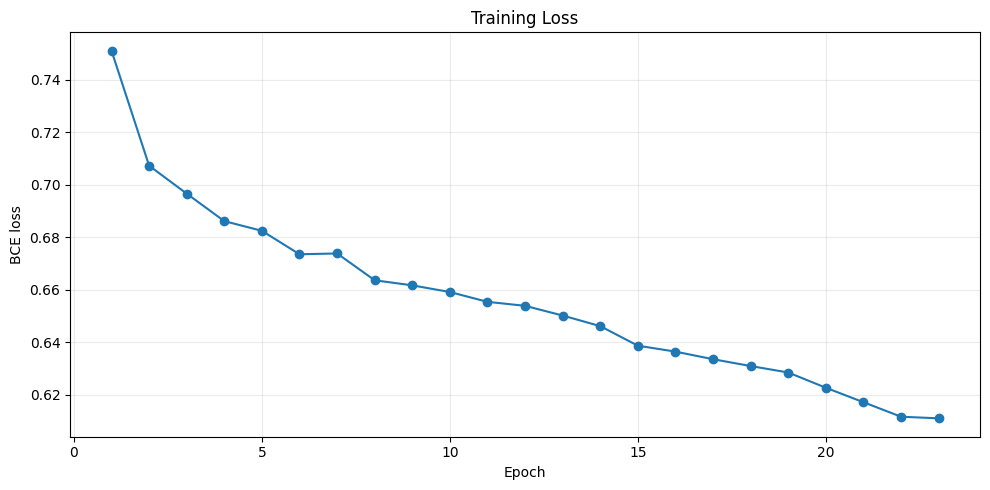

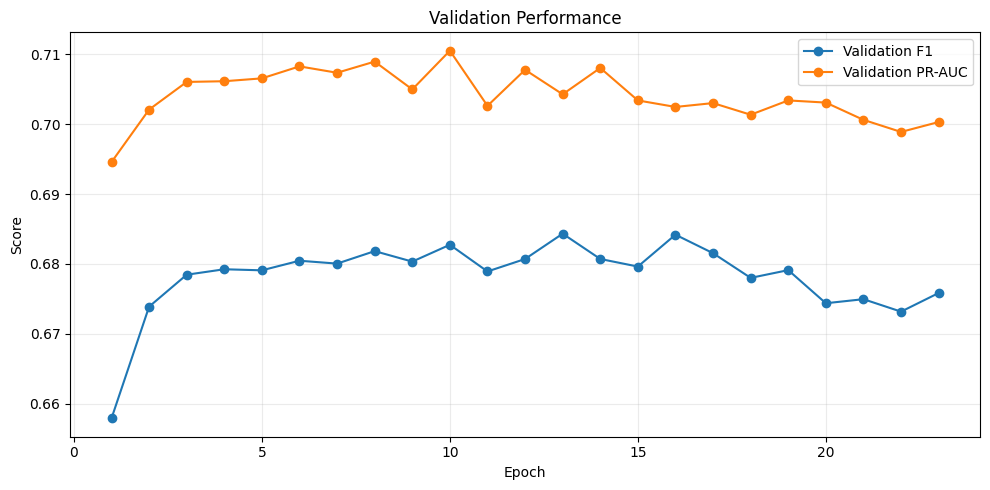

In [15]:
# ============================================================
# 13/15 — TRAINING CURVES
# ============================================================
history_df = pd.DataFrame(history)

plt.figure(figsize=(10, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
)
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Training Loss")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(PREVIEW / "training_loss.png", dpi=160)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1",
)
plt.plot(
    history_df["epoch"],
    history_df["val_pr_auc"],
    marker="o",
    label="Validation PR-AUC",
)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(PREVIEW / "validation_metrics.png", dpi=160)
plt.show()

[TEST METRICS]
{
  "accuracy": 0.7225352112676057,
  "precision": 0.5761024182076814,
  "recall": 0.8083832335329342,
  "f1": 0.6727574750830565,
  "roc_auc": 0.8202398250289412,
  "pr_auc": 0.7188205435305905,
  "threshold_from_validation": 0.405
}


,video,history_start_seconds,history_end_seconds,target_seconds,target,probability,prediction,correct
0,video_016.avi,0.0,14.0,16.0,0,0.611077,1,False
1,video_016.avi,2.0,16.0,18.0,1,0.391848,0,False
2,video_016.avi,4.0,18.0,20.0,1,0.596213,1,True
3,video_016.avi,6.0,20.0,22.0,1,0.831326,1,True
4,video_016.avi,8.0,22.0,24.0,0,0.806065,1,False
5,video_016.avi,10.0,24.0,26.0,0,0.493558,1,False
6,video_016.avi,12.0,26.0,28.0,0,0.184637,0,True
7,video_016.avi,14.0,28.0,30.0,0,0.106737,0,True
8,video_016.avi,16.0,30.0,32.0,0,0.111340,0,True
9,video_016.avi,18.0,32.0,34.0,0,0.128849,0,True


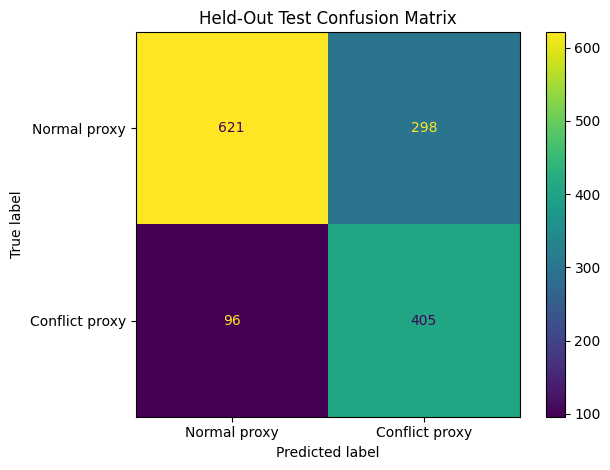

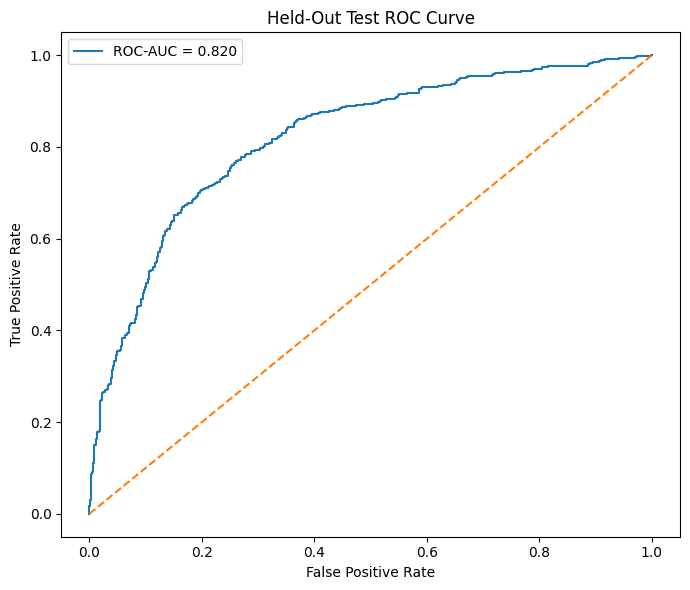

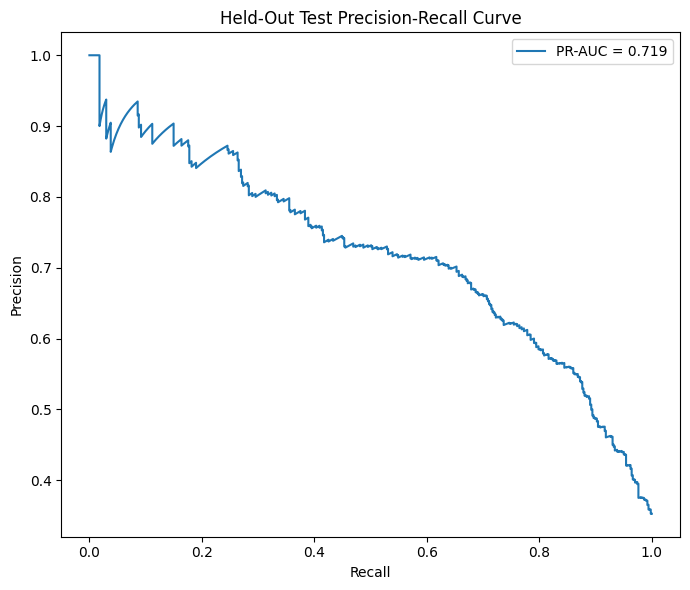

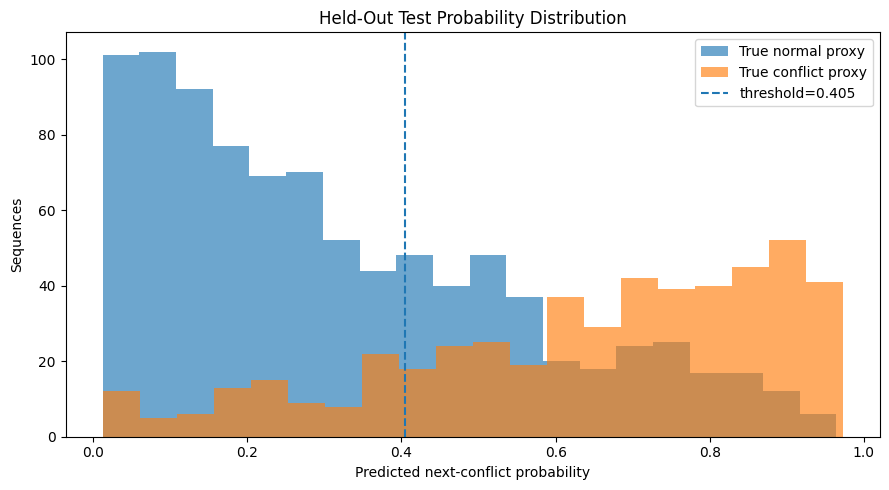

In [16]:
# ============================================================
# 14/15 — HELD-OUT TEST EVALUATION + PREVIEWS
# ============================================================
checkpoint = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False,  # trusted checkpoint created by this notebook
)

net.load_state_dict(
    checkpoint["model_state_dict"]
)

threshold = float(
    checkpoint["threshold"]
)

test_true, test_prob = collect_predictions(
    net,
    test_loader,
)

test_pred = (
    test_prob >= threshold
).astype(int)

metrics = {
    "accuracy": float(
        accuracy_score(
            test_true,
            test_pred,
        )
    ),
    "precision": float(
        precision_score(
            test_true,
            test_pred,
            zero_division=0,
        )
    ),
    "recall": float(
        recall_score(
            test_true,
            test_pred,
            zero_division=0,
        )
    ),
    "f1": float(
        f1_score(
            test_true,
            test_pred,
            zero_division=0,
        )
    ),
    "roc_auc": float(
        roc_auc_score(
            test_true,
            test_prob,
        )
    ),
    "pr_auc": float(
        average_precision_score(
            test_true,
            test_prob,
        )
    ),
    "threshold_from_validation": threshold,
}

print("[TEST METRICS]")
print(json.dumps(metrics, indent=2))

with open(
    REP / "test_metrics.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(metrics, f, indent=2)

prediction_df = meta_test.copy()
prediction_df["probability"] = test_prob
prediction_df["prediction"] = test_pred
prediction_df["correct"] = (
    prediction_df["target"]
    == prediction_df["prediction"]
)

prediction_df.to_csv(
    REP / "test_predictions.csv",
    index=False,
)

display(prediction_df.head(20))

# Confusion matrix
cm = confusion_matrix(
    test_true,
    test_pred,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal proxy",
        "Conflict proxy",
    ],
)

disp.plot(
    values_format="d",
)

plt.title("Held-Out Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    PREVIEW / "test_confusion_matrix.png",
    dpi=160,
)
plt.show()

# ROC
fpr, tpr, _ = roc_curve(
    test_true,
    test_prob,
)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {metrics['roc_auc']:.3f}",
)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Held-Out Test ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(PREVIEW / "test_roc_curve.png", dpi=160)
plt.show()

# PR
precision_curve, recall_curve, _ = precision_recall_curve(
    test_true,
    test_prob,
)

plt.figure(figsize=(7, 6))
plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC = {metrics['pr_auc']:.3f}",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Held-Out Test Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(PREVIEW / "test_pr_curve.png", dpi=160)
plt.show()

# Prediction probability distribution
plt.figure(figsize=(9, 5))
plt.hist(
    test_prob[test_true == 0],
    bins=20,
    alpha=0.65,
    label="True normal proxy",
)
plt.hist(
    test_prob[test_true == 1],
    bins=20,
    alpha=0.65,
    label="True conflict proxy",
)
plt.axvline(
    threshold,
    linestyle="--",
    label=f"threshold={threshold:.3f}",
)
plt.xlabel("Predicted next-conflict probability")
plt.ylabel("Sequences")
plt.title("Held-Out Test Probability Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(
    PREVIEW / "test_probability_distribution.png",
    dpi=160,
)
plt.show()

In [17]:
# ============================================================
# 15/15 — FINAL SUMMARY + PACKAGE
# ============================================================
summary = {
    "project": "8% — Crosswalk Safety",
    "version": "v4",
    "pipeline": (
        "YOLO11n bounding-box preprocessing -> "
        "engineered spatial/motion features -> "
        "Temporal Conv1D + BiLSTM"
    ),
    "videos_total": int(frame_df["video"].nunique()),
    "sampled_frames_total": int(len(frame_df)),
    "sample_every_seconds": SAMPLE_EVERY_SECONDS,
    "sequence_length": SEQUENCE_LENGTH,
    "history_seconds": SEQUENCE_LENGTH * SAMPLE_EVERY_SECONDS,
    "predict_horizon_steps": PREDICT_HORIZON_STEPS,
    "prediction_horizon_seconds": (
        PREDICT_HORIZON_STEPS
        * SAMPLE_EVERY_SECONDS
    ),
    "feature_count": len(FEATURE_COLUMNS),
    "train_videos": len(train_videos),
    "val_videos": len(val_videos),
    "test_videos": len(test_videos),
    "train_sequences": int(len(X_train)),
    "val_sequences": int(len(X_val)),
    "test_sequences": int(len(X_test)),
    "model": "Temporal Conv1D + BiLSTM",
    "best_validation_f1": float(checkpoint["best_val_f1"]),
    "validation_threshold": threshold,
    "held_out_test_metrics": metrics,
    "target_definition": (
        "weak/pseudo label: conflict_proxy at NEXT sampled frame, "
        "where proxy = pedestrian_in_ROI > 0 AND vehicle_in_ROI > 0"
    ),
    "scope_note": (
        "This is a weakly supervised temporal conflict-screening model. "
        "Metrics measure agreement with the proxy label, not validated "
        "traffic-violation accuracy."
    ),
}

with open(
    OUT / "final_summary.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        summary,
        f,
        indent=2,
    )

print(json.dumps(summary, indent=2), flush=True)

zip_path = shutil.make_archive(
    "/kaggle/working/crosswalk_safety_8pct_v4_TEMPORAL_TRAINED_outputs",
    "zip",
    root_dir=OUT,
)

print("[ZIP]", zip_path, flush=True)
print(
    "[DONE] CROSSWALK SAFETY v4 "
    "TEMPORAL TRAINING PIPELINE FINISHED",
    flush=True,
)

{
  "project": "8% \u2014 Crosswalk Safety",
  "version": "v4",
  "pipeline": "YOLO11n bounding-box preprocessing -> engineered spatial/motion features -> Temporal Conv1D + BiLSTM",
  "videos_total": 120,
  "sampled_frames_total": 18000,
  "sample_every_seconds": 2.0,
  "sequence_length": 8,
  "history_seconds": 16.0,
  "predict_horizon_steps": 1,
  "prediction_horizon_seconds": 2.0,
  "feature_count": 21,
  "train_videos": 91,
  "val_videos": 19,
  "test_videos": 10,
  "train_sequences": 12922,
  "val_sequences": 2698,
  "test_sequences": 1420,
  "model": "Temporal Conv1D + BiLSTM",
  "best_validation_f1": 0.6843286933093848,
  "validation_threshold": 0.405,
  "held_out_test_metrics": {
    "accuracy": 0.7225352112676057,
    "precision": 0.5761024182076814,
    "recall": 0.8083832335329342,
    "f1": 0.6727574750830565,
    "roc_auc": 0.8202398250289412,
    "pr_auc": 0.7188205435305905,
    "threshold_from_validation": 0.405
  },
  "target_definition": "weak/pseudo label: conflict_p